# Surf zone lab: one SWASH case

In this notebook you set up a coast and some waves, run the **SWASH** wave model, and look at what happens between offshore and the shoreline. Each run is one **case**. You can run the notebook several times with different values and compare the cases at the end.

**You don't need to know Python.** You only change the values in the cells marked ✏️. All the other cells you just run.

### How to use a notebook

- Click a grey code cell and press **Shift + Enter** to run it, then go on to the next one.
- `In [*]` next to a cell means it is still running. Wait until a number appears.
- Run the cells **in order, from the top**. If something looks wrong, start again from the top.
- Lines starting with `#` are comments for you. The computer ignores them.

### Rules when you change a value

| Do | Don't |
|---|---|
| `Hs = 2.5` (decimals with a **point**) | `Hs = 2,5` |
| `WAVE = "mono"` (words **in quotes**) | `WAVE = mono` |
| `Tp = 10` (numbers **without** quotes) | `Tp = "10"` |
| `Hs` | `hs`: upper and lower case matter |

Your group's task is in `GROUP_TASKS.md`. If you see a red error, look at **Help** at the end.

## 0. Load the tools

Run once. Nothing appears; that is normal.

In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pandas as pd

from scripts.wrappers import SwashModelWrapper_ondas
from scripts.bathymetry import linear_profile, reef_profile
from scripts.plots import plot_case_config
from scripts.results import (save_case, load_case, saved_cases, case_table,
                             plot_results, plot_xt, animate_case)

## 01. Define the case

### ✏️ Case name

Every run needs its **own name**. It becomes a folder in `cases/`, and it is how you find the case again to compare it.
Use letters, numbers and `_` only, no spaces. If you reuse a name, the old case is overwritten.

Tip: start with your group letter and say what is special, e.g. `"B_Hs4"` or `"A_mono"`.

In [2]:
CASE_NAME = "test_mono"

#### Necessary paths

Where the SWASH template is, and where the cases are written. Don't change.

In [3]:
templates_dir = op.join(os.getcwd(), 'templates', 'templates_test')
output_dir = op.join(os.getcwd(), 'cases')

### ✏️ Hydrodynamic forcing

| Value | What it is | Typical values |
|---|---|---|
| `WAVE` | `"mono"`: regular waves, all equal (monochromatic). `"jonswap"`: a real sea, waves of all sizes arriving in groups (irregular, JONSWAP spectrum) | `"mono"` or `"jonswap"` |
| `Hs` | Significant wave height offshore (m) | 0.5 to 4 |
| `Tp` | Peak period (s) | 5 to 16 |
| `WL` | Still water level (m): tide or storm surge. `+1` is 1 m above normal | −1.5 to +1.5 |
| `GAMMA` | Only for `"jonswap"`: how peaked the spectrum is. 1 = broad windsea, 3.3 = standard, 7 = narrow swell | 1 to 7 |
| `MANNING_N` | Bed roughness (Manning n), the same along the whole profile. Smooth sand ≈ 0.01, rough coral 0.1 to 0.2 | 0.01 to 0.2 |

A `"mono"` wave is run with height `Hs / √2`, so it carries **the same energy** as a `"jonswap"` sea with the same `Hs`.

`Hs_L0` is the wave steepness (height over deep-water wavelength). It should be between 0.005 (long swell) and 0.05 (steep storm waves).

In [4]:
WAVE = "mono"   # "mono" or "jonswap"
Hs = 2.5           # m
Tp = 10            # s
WL = 0.0           # m
GAMMA = 3.3        # only used with "jonswap"
MANNING_N = 0.01   # bed roughness, whole profile

Hs_L0 = (2 * np.pi * Hs) / (9.81 * Tp ** 2)   # wave steepness, don't change
print(f"Hs/L0 = {Hs_L0:.4f}  (should be between 0.005 and 0.05)")

Hs/L0 = 0.0160  (should be between 0.005 and 0.05)


### ✏️ Create bathymetry

Choose the coast with `PROFILE`, then change the numbers for **that** coast only. The others are ignored.

**`"beach"`**: a flat bottom, then a sandy beach with a constant slope. You can add a sandbar.

| Value | What it is | Typical values |
|---|---|---|
| `h0` | Bed level offshore (m, negative = under water) | −12 |
| `m` | Beach slope. `1/30` means it rises 1 m every 30 m | 0.025 (1/40, gentle) to 0.07 (1/15, steep) |
| `bar_height` | Height of a sandbar on the beach (m). `0` = no bar | 0 to 2.5 |
| `bar_x` | Where the bar crest is (m from the offshore end) | 550 to 750 |

**`"reef"`**: a coral reef: a slope, a flat reef top, and a steep beach behind it.

| Value | What it is | Typical values |
|---|---|---|
| `reef_depth` | Water depth on top of the reef when `WL = 0` (m) | 1 to 4 |
| `reef_width` | Width of the reef flat (m) | 100 to 400 |

`x` is the distance from the offshore end and `z` the bed elevation (positive up), every 1 m.

In [5]:
PROFILE = "beach"   # "beach" or "reef"

# ---- beach ----
h0 = -12            # offshore bed level (m)
m = 1 / 30          # beach slope
bar_height = 0      # sandbar height (m), 0 = no bar
bar_x = 650         # sandbar crest position (m)

# ---- reef ----
reef_depth = 2.5    # water depth on the reef flat (m)
reef_width = 200    # reef flat width (m)

Build the profile from the values above. Just run it.

In [6]:
if PROFILE == "beach":
    Ltotal = 1000   # profile length (m)
    Wfore = 400     # flat part before the slope (m)
    x_profile, depth_array = linear_profile(h0=h0, Ltotal=Ltotal, Wconst=Wfore, slope=m)
    depth_array = depth_array + bar_height * np.exp(-((x_profile - bar_x) / 40) ** 2)

elif PROFILE == "reef":
    x_profile, depth_array = reef_profile(dx=1, h0=15, Slope1=0.05, Slope2=0.1,
                                          Wreef=reef_width, Wfore=500, bCrest=10,
                                          emsl=reef_depth)

else:
    raise ValueError('PROFILE must be "beach" or "reef"')

x_profile = np.arange(len(depth_array))
if depth_array[-1] - WL < 3:
    raise ValueError("The beach is too low for this water level. Use a steeper slope (m >= 0.025).")

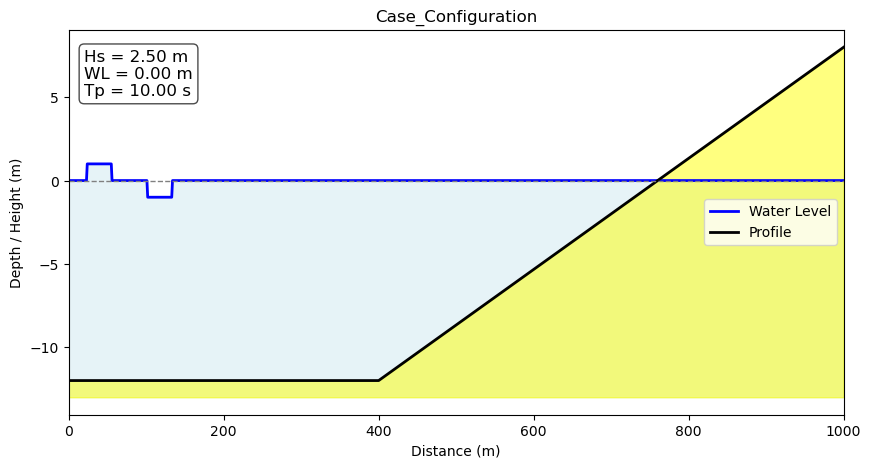

In [7]:
plot_case_config(x=x_profile, z=depth_array, wave_height=Hs, wave_period=Tp, WL=WL)

## 02. Set up the model

Puts all the values above into the SWASH wrapper. Don't change, just run.

- `metamodel_parameters`: what describes this case (waves, water level, friction). Our names `wave_type`, `jonswap_gamma` and `manning_n` are different from bluemath's own parameters on purpose.
- `fixed_parameters`: how the model runs. SWASH runs `warmup + comptime` = 1200 s of sea; the first 300 s (warmup, while the waves arrive and the sea settles) are thrown away, and 900 s are analysed.

In [8]:
metamodel_parameters = pd.DataFrame({
    'Hs': Hs,
    'Hs_L0': Hs_L0,
    'WL': WL,
    'wave_type': WAVE,
    'jonswap_gamma': GAMMA,
    'manning_n': MANNING_N,
}, index=[0]).to_dict(orient='list')

fixed_parameters = {
    "dxinp": 1,                    # bathymetry grid spacing (m)
    "comptime": 900,               # analysed duration (s)
    "warmup": 300,                 # warmup duration, removed (s)
    "n_nodes_per_wavelength": 60,  # number of nodes per wavelength
}

swash_model = SwashModelWrapper_ondas(
    templates_dir=templates_dir,
    metamodel_parameters=metamodel_parameters,
    fixed_parameters=fixed_parameters,
    output_dir=output_dir,
    depth_array=-depth_array,
)

2026-11-09 11:56:58,344 - SwashModelWrapper_ondas - WARNING - Parameter wave_type is not in the default_parameters
2026-11-09 11:56:58,346 - SwashModelWrapper_ondas - WARNING - Parameter jonswap_gamma is not in the default_parameters
2026-11-09 11:56:58,347 - SwashModelWrapper_ondas - WARNING - Parameter manning_n is not in the default_parameters


In [9]:
swash_model.build_cases(cases_name_format=lambda ctx: CASE_NAME)

## 03. Run SWASH

This takes **a few minutes**. Wait until `In [*]` turns into a number.

In [10]:
swash_model.run_cases(launcher='serial')

## 04. Postprocess and save

Calculates the wave heights, setup and runup, and saves the case under `CASE_NAME` so you can compare it later.

In [11]:
vars_to_postprocess = ["Msetup", "Hrms", "Hfreqs", "Ru2"]
postprocessed = swash_model.postprocess_cases(output_vars=vars_to_postprocess).isel(case_num=0)

output_data = xr.open_dataset(op.join(output_dir, CASE_NAME, 'output.nc'))

save_case(CASE_NAME, postprocessed, x_profile, depth_array, WL, Hs, Tp, WAVE,
          output_dir, MANNING_N, output_data)

Saved as 'test_mono'. Ru2 = 0.54 m


## 05. Results

### Along the profile

From offshore (left) to the shoreline (right):

1. **Hss**: height of the short waves (periods below 25 s). It grows a little as waves slow down in shallow water (*shoaling*), then falls fast once they break.
2. **IG**: height of the *infragravity* waves, long waves with periods above 25 s. They are made by wave groups.
3. **Mean level**: the average water level. It drops slightly before breaking (*setdown*) and rises after breaking (*setup*).
4. **Bed**, with the still water level dashed.

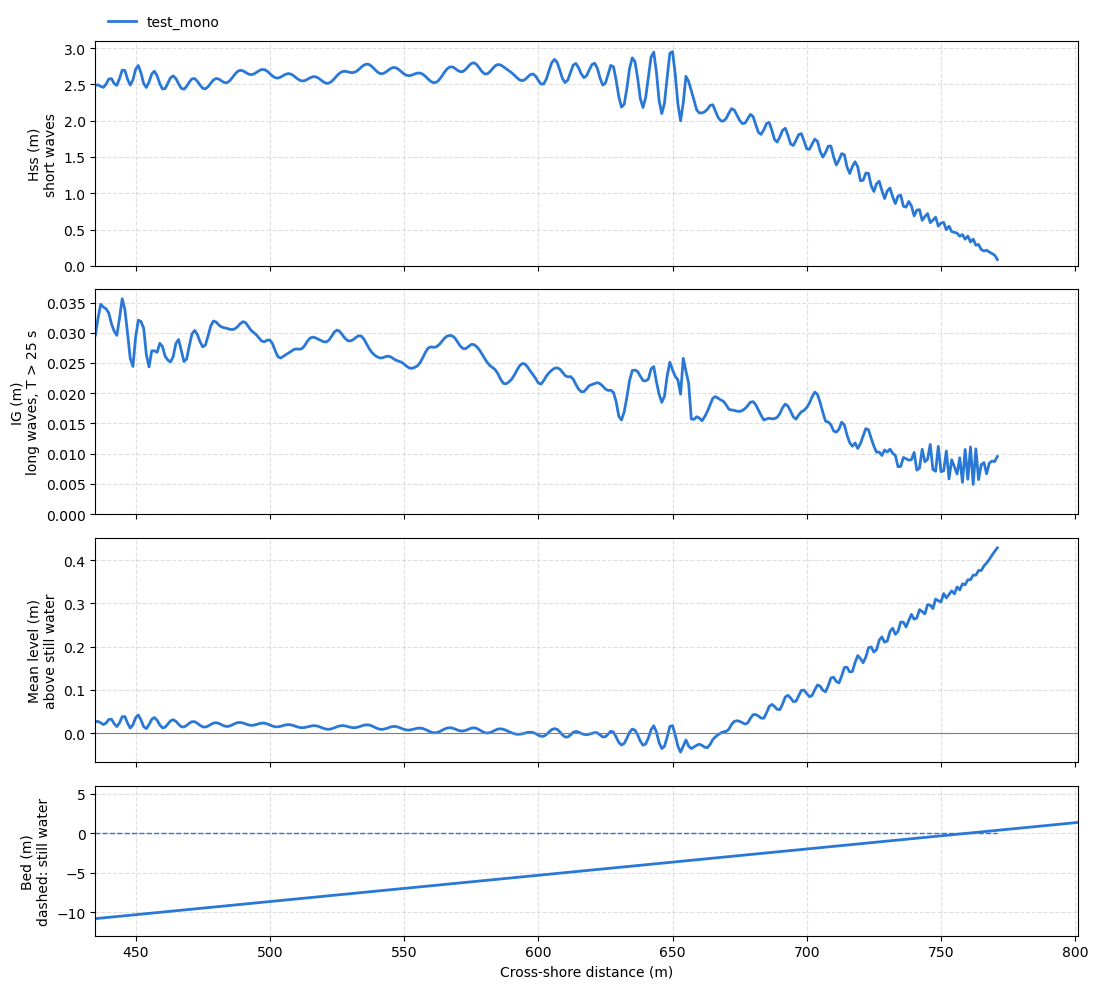

In [12]:
plot_results(CASE_NAME)

### The numbers

| Row | Meaning |
|---|---|
| x_break | Where waves start breaking: where Hss has lost 10% of its maximum |
| Hss/h at break | Wave height divided by depth there. Theory for a single wave: about 0.78 |
| Hss, h=1 m | Short-wave height where the water is 1 m deep, inside the surf zone |
| IG, h=1 m | Long-wave height at the same place |
| IG/Hss | Above 1: the long waves are bigger than the short ones |
| Setup at shore | How much the mean water level has risen where still water meets the beach |
| Ru2 | Runup: height on the beach (above still water) reached by the highest 2% of uprushes |
| Ru2 + WL | The same, measured from normal sea level. **This is the number for flooding** |

`Ru2` comes from 15 minutes of sea, so differences of a few centimetres are not meaningful.

In [13]:
case_table([CASE_NAME])

,test_mono
wave,mono
Hs (m),2.5
Tp (s),10.0
WL (m),0.0
Manning n,0.01
x_break (m),650.0
Hss/h at break,0.66
"Hss, h=1 m (m)",0.89
"IG, h=1 m (m)",0.01
IG/Hss,0.01


### The waves in time

A map of the water level: distance across, time going up. A stripe leaning **to the right** as time goes up is a wave travelling **to the shore**; leaning **to the left**, a wave going **back out to sea**. The right panel keeps only the long waves.

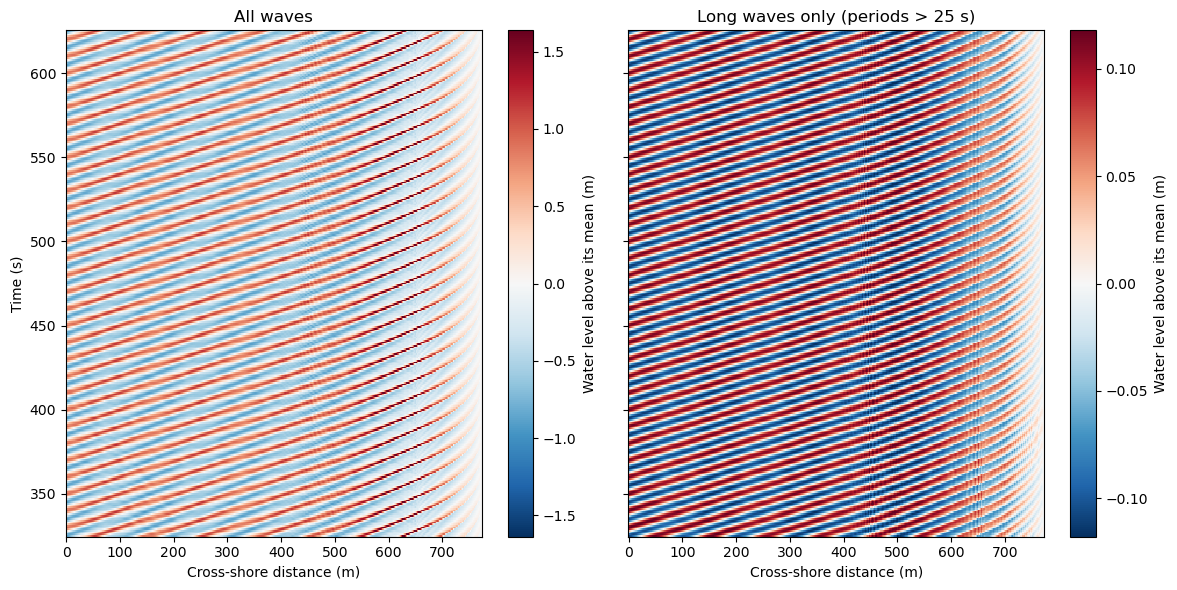

In [14]:
plot_xt(output_data, x_profile, depth_array, WL)

### Watch it

150 s of the water surface. Press ▶ under the figure.

In [15]:
animate_case(output_data, x_profile, depth_array, WL, seconds=150)

## 06. Compare cases

To compare, go back to **01**, change one value **and the case name**, and run the notebook again down to **04**. Then come here.

This cell lists every saved case:

In [16]:
saved_cases()

['test_jonswap', 'test_mono']

✏️ Write the names you want to compare, in quotes, separated by commas, inside the square brackets (up to 6).

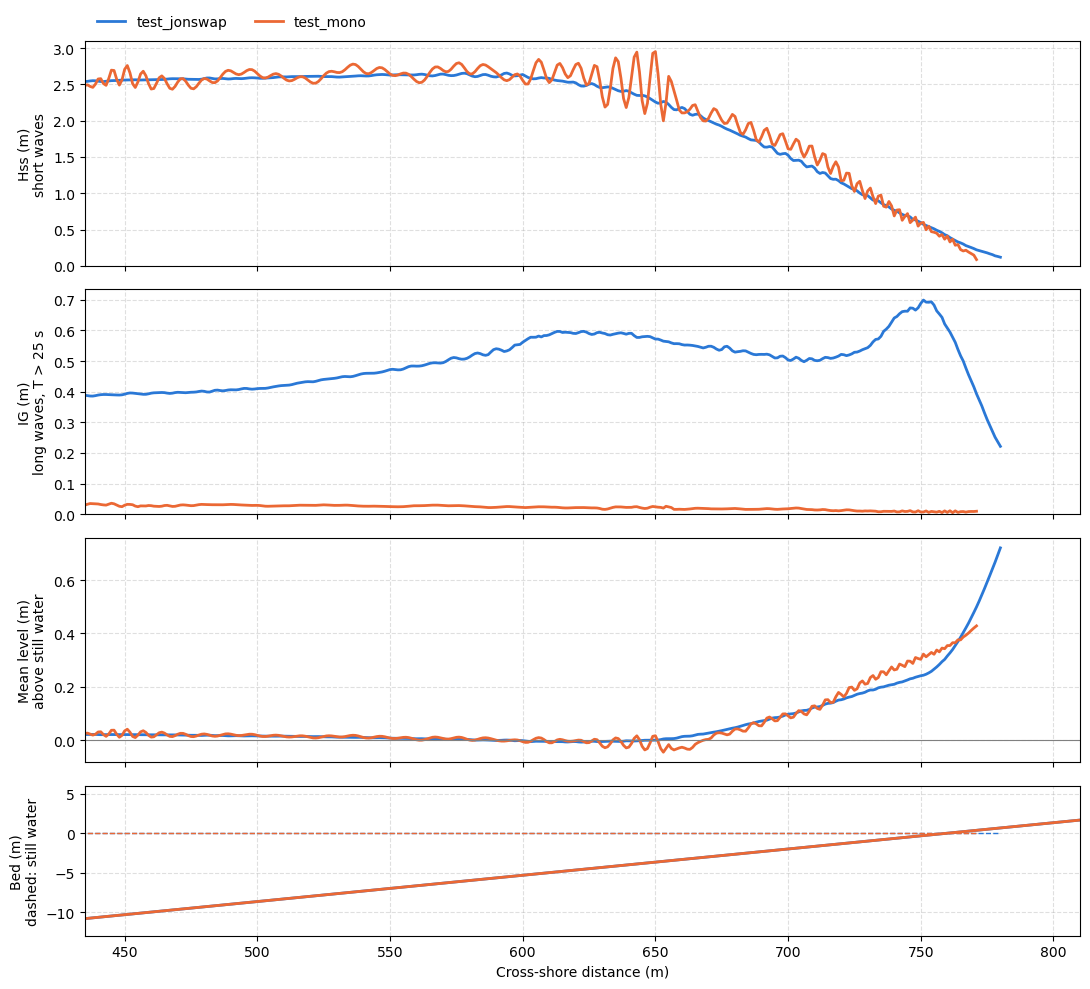

,test_jonswap,test_mono
wave,jonswap,mono
Hs (m),2.5,2.5
Tp (s),10.0,10.0
WL (m),0.0,0.0
Manning n,0.01,0.01
x_break (m),640.0,650.0
Hss/h at break,0.59,0.66
"Hss, h=1 m (m)",0.83,0.89
"IG, h=1 m (m)",0.6,0.01
IG/Hss,0.73,0.01


In [17]:
CASES = ["test_jonswap","test_mono"]

plot_results(CASES)
case_table(CASES)